# Color Classification with KNN -- Bilingual Persian/English Color Naming
## Two-Stage Hierarchical Color Naming using K-Nearest Neighbors

---

### Project Overview

This notebook implements a **Two-Stage Hierarchical KNN** pipeline that predicts
the full bilingual color name (English + Persian) for any RGB hex code input.

**Dataset:** [KopolArt Color Collection](https://kopolart.ir/colors), curated by
**Ali Yousefi (KopolArt)** and licensed under **CC BY 4.0**. Required attribution:
**کپل‌آرت – Ali Yousefi** with a direct link to <https://kopolart.ir/colors>.
See `data/README.md` for the full schema and reuse terms.

**The Core Challenge -- Class Sparsity:**
The dataset has 608 color samples and 313 unique English shade names
(331 unique Persian names). Many shades appear only once or twice, so a naive
single-stage 1-NN reaches only ~13% strict exact-match accuracy (a tuned K=5
variant reaches ~17%). A prediction of
"Dark Red" instead of "Red" counts as a total failure even though both are
perceptually the same color family.

**The Solution -- Coarse-to-Fine Classification:**

| Stage | Method | Output |
|-------|--------|--------|
| **Stage 1** | KNN on cylindrical HSV + RGB features | Base color family (e.g. Green) |
| **Stage 2** | Nearest-neighbor search in CIE L*a*b* space | Exact shade name (e.g. Dark Green) |

### Steps in This Notebook:
1. Dataset loading and color space feature engineering
2. Exploratory Data Analysis (EDA) -- distributions, 3D RGB cube, Hue vs. Saturation
3. Cylindrical HSV + RGB feature extraction (solves the Hue discontinuity problem)
4. Train/test split and StandardScaler feature normalization
5. Hyperparameter tuning -- cross-validation K search
6. Model training and multi-tier evaluation (baseline, Stage 1, and end-to-end two-stage)
7. Confusion matrix analysis over 14 core color families (absolute + normalized heatmaps)
8. Visual test swatches -- exact match vs. human-vision match vs. mismatch
9. Pipeline serialization to model.pkl
10. Live two-stage inference demo with CIE Lab Delta-E visualization

In [1]:
import os
import sys
import re
import colorsys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the repository root is on sys.path so that prepare_dataset.py is
# importable regardless of where Jupyter's kernel CWD is set.
_cwd = os.getcwd()
if _cwd not in sys.path:
    sys.path.insert(0, _cwd)

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

from prepare_dataset import hex_to_rgb, rgb_to_lab, EN_TO_FA_BASE

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
sns.set_theme(style='whitegrid')

print("All libraries successfully imported!")

All libraries successfully imported!


## Step 1: Dataset Loading & Color Space Feature Engineering

The enriched dataset `data/colors.csv` contains 18 columns derived from raw hex codes:

| Column group | Features |
|---|---|
| Raw | Persian Name, EnglishName, HexCode (24 bit) |
| Integer RGB | Red (8 bit), Green (8 bit), Blue (8 bit) |
| Angular | Hue (degrees) 0-360 |
| HSL | HSL.S (%), HSL.L (%) |
| HSV | HSV.S (%), HSV.V (%) |
| Perceptual | Lab_L, Lab_A, Lab_B -- CIE L*a*b* (Delta-E distance) |
| Labels | Base_English, Base_Persian -- coarse color family |

The CIE L*a*b* space is **perceptually uniform**: Euclidean distance in this space
(Delta-E) directly corresponds to human-perceived color difference.

In [2]:
csv_path = 'data/colors.csv' if os.path.exists('data/colors.csv') else 'colors.csv'
df_colors = pd.read_csv(csv_path, encoding='utf-8-sig')

print(f"Dataset loaded from : {csv_path}")
print(f"Shape               : {df_colors.shape}")
print(f"Columns             : {df_colors.columns.tolist()}\n")
display(df_colors[['Persian Name', 'EnglishName', 'HexCode (24 bit)',
                    'Hue (degrees)', 'Base_English', 'Base_Persian']].head(10))

Dataset loaded from : data/colors.csv
Shape               : (608, 18)
Columns             : ['Persian Name', 'EnglishName', 'HexCode (24 bit)', 'Red (8 bit)', 'Green (8 bit)', 'Blue (8 bit)', 'Hue (degrees)', 'HSL.S (%)', 'HSL.L (%)', 'HSV.S (%)', 'HSV.V (%)', 'Lab_L', 'Lab_A', 'Lab_B', 'Base_English', 'Base_Persian', 'hex', 'name']



,Persian Name,EnglishName,HexCode (24 bit),Hue (degrees),Base_English,Base_Persian
0,سبز تیره,Dark Green,#388E3C,122.8,Green,سبز
1,سبز,Green,#8BC34A,87.8,Green,سبز
2,زرد,Yellow,#FEED30,55.0,Yellow,زرد
3,نارنجی,Orange,#FF6A38,15.1,Orange,نارنجی
4,بنفش تیره,Dark Violet,#B000B9,297.1,Purple,بنفش
5,صورتی گلبهی,Salmon Pink,#FF5F7E,348.4,Salmon Pink,صورتی گلبهی
6,نارنجی ملایم,Orange,#FFAB4C,31.8,Orange,نارنجی
7,سرمه‌ای سیر,Dark Navy Blue,#142F43,205.5,Navy Blue,سرمه‌ای
8,آبی کاربنی روشن,Bright Royal Blue,#5463FF,234.7,Royal Blue,آبی کاربنی
9,زرد,Golden Yellow,#FFC300,45.9,Golden Yellow,زرد طلایی


## Step 2: Exploratory Data Analysis (EDA)

Before building the model, we explore:
- How many unique color names and base families exist
- Distribution of samples across base color categories
- How colors are spread across the RGB cube and Hue-Saturation space

Total color samples   : 608
Unique English names  : 313
Unique Persian names  : 331
Base color categories : 33


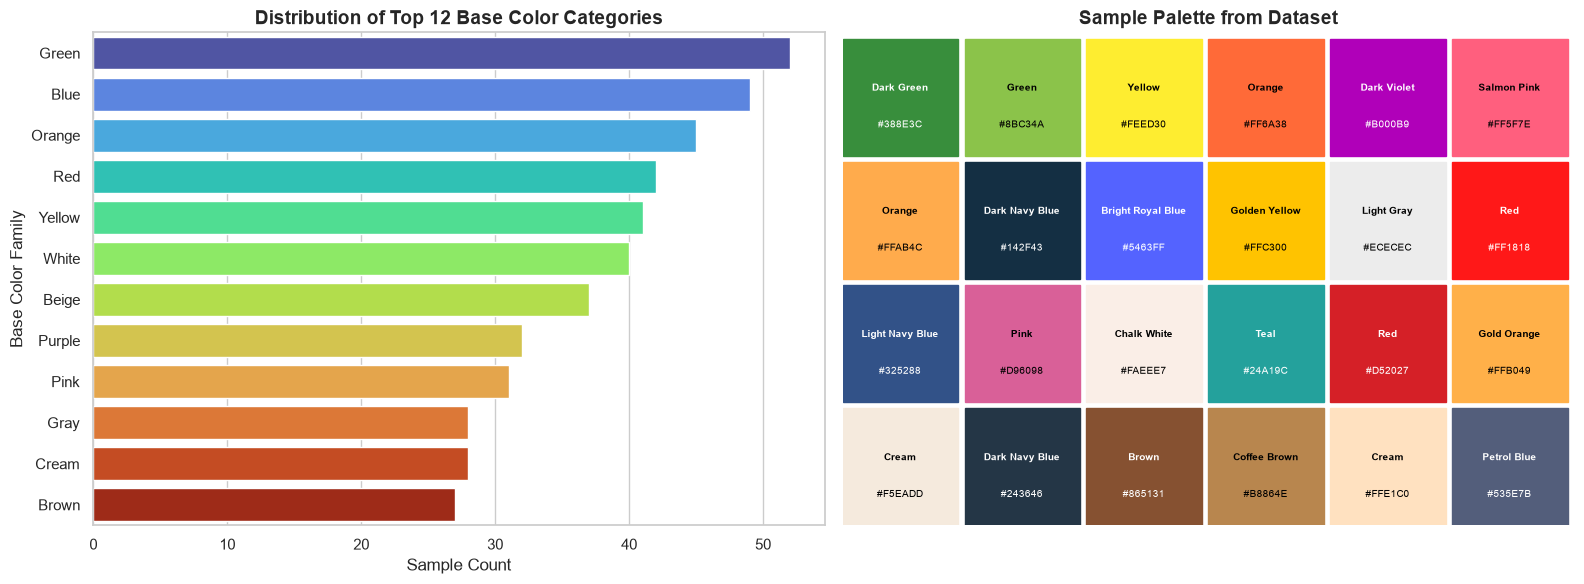

In [3]:
print(f"Total color samples   : {len(df_colors)}")
print(f"Unique English names  : {df_colors['EnglishName'].nunique()}")
print(f"Unique Persian names  : {df_colors['Persian Name'].nunique()}")
print(f"Base color categories : {df_colors['Base_English'].nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: distribution of base color categories
base_counts = df_colors['Base_English'].value_counts().head(12)
sns.barplot(x=base_counts.values, y=base_counts.index, ax=axes[0], palette='turbo')
axes[0].set_title('Distribution of Top 12 Base Color Categories', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sample Count')
axes[0].set_ylabel('Base Color Family')

# Right: palette swatches of the first 24 colors
sample_subset = df_colors.head(24)
n_cols, n_rows = 6, 4
for i, (_, row) in enumerate(sample_subset.iterrows()):
    r_idx, c_idx = divmod(i, n_cols)
    rect = plt.Rectangle((c_idx, n_rows - 1 - r_idx), 0.95, 0.95, color=row['HexCode (24 bit)'])
    axes[1].add_patch(rect)
    rv, gv, bv = hex_to_rgb(row['HexCode (24 bit)'])
    lum = (0.299 * rv + 0.587 * gv + 0.114 * bv) / 255.0
    tc = 'black' if lum > 0.5 else 'white'
    axes[1].text(c_idx + 0.47, n_rows - 1 - r_idx + 0.55,
                 row['EnglishName'], color=tc, ha='center', va='center',
                 fontsize=7.5, fontweight='bold')
    axes[1].text(c_idx + 0.47, n_rows - 1 - r_idx + 0.25,
                 row['HexCode (24 bit)'], color=tc, ha='center', va='center', fontsize=7)

axes[1].set_xlim(0, n_cols); axes[1].set_ylim(0, n_rows); axes[1].axis('off')
axes[1].set_title('Sample Palette from Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

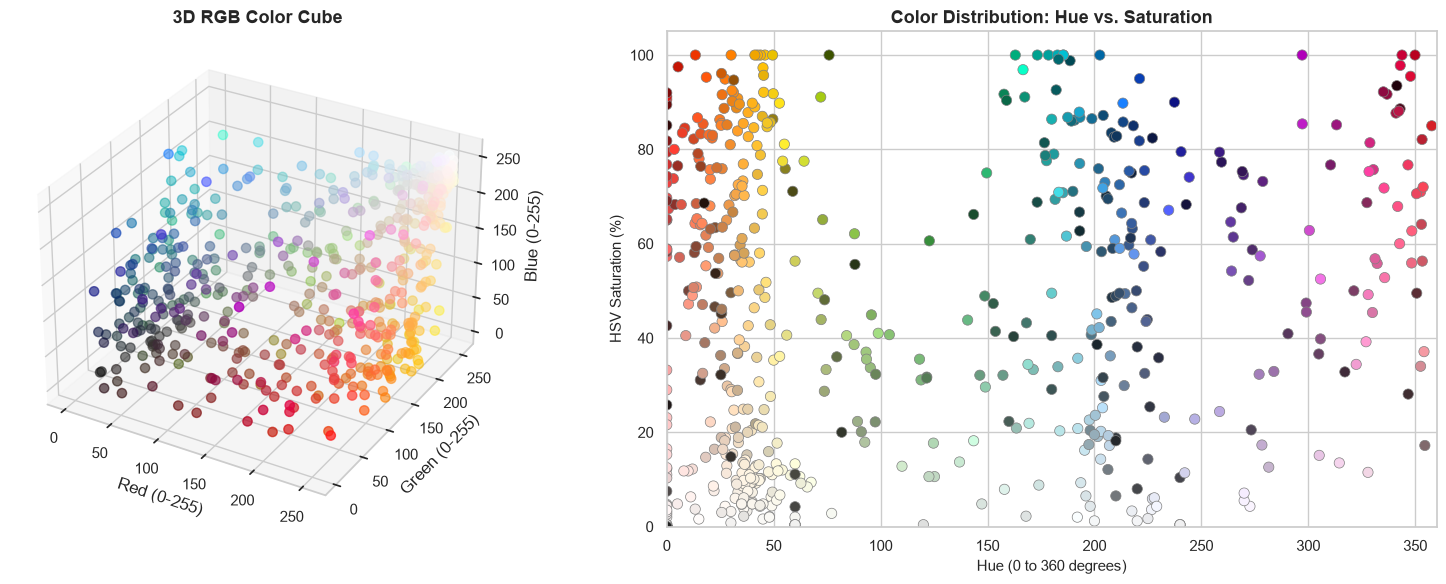

In [4]:
fig = plt.figure(figsize=(16, 6))
rgb_norm = df_colors[['Red (8 bit)', 'Green (8 bit)', 'Blue (8 bit)']].values / 255.0

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(df_colors['Red (8 bit)'], df_colors['Green (8 bit)'], df_colors['Blue (8 bit)'],
            c=rgb_norm, s=45, alpha=0.9)
ax1.set_xlabel('Red (0-255)'); ax1.set_ylabel('Green (0-255)'); ax1.set_zlabel('Blue (0-255)')
ax1.set_title('3D RGB Color Cube', fontsize=13, fontweight='bold')

ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(df_colors['Hue (degrees)'], df_colors['HSV.S (%)'],
            c=rgb_norm, s=55, edgecolors='gray', linewidth=0.5)
ax2.set_xlabel('Hue (0 to 360 degrees)', fontsize=11)
ax2.set_ylabel('HSV Saturation (%)', fontsize=11)
ax2.set_title('Color Distribution: Hue vs. Saturation', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 360); ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()

## Step 3: Feature Engineering -- Cylindrical HSV + Normalized RGB

**Why not use raw Hue directly?**
Hue is an angular value that wraps at 360 degrees. A red at 358 deg and a red at 2 deg
are visually almost identical, but their raw numeric difference is 356 -- huge for KNN.

**The Cylindrical Encoding:**

```
x1 = S * cos(2 * pi * H)    # circular Hue component 1
x2 = S * sin(2 * pi * H)    # circular Hue component 2
x3 = V                       # Value (brightness)
x4 = R / 255                 # normalized Red
x5 = G / 255                 # normalized Green
x6 = B / 255                 # normalized Blue
```

When S is near 0 (neutral colors: gray, white, black), both circular components
collapse to near-zero, eliminating meaningless Hue noise for achromatic colors.

In [5]:
# Core color family patterns for confusion matrix and human-vision accuracy.
# Maps detailed names (e.g. "Navy Blue") to broad families (e.g. "Blue").
CORE_PATTERNS = [
    ('Red',           r'\b(red|crimson|ruby|scarlet|burgundy|maroon|rose|cherry|wine|cerise)\b'),
    ('Blue',          r'\b(blue|navy|cyan|azure|indigo|sapphire|cerulean|sky|cobalt|denim|petrol|royal)\b'),
    ('Teal',          r'\b(teal|turquoise|aqua)\b'),
    ('Green',         r'\b(green|emerald|lime|olive|mint|sage|jade|forest|moss|pistachio|army)\b'),
    ('Yellow',        r'\b(yellow|amber|lemon|mustard|gold|golden|saffron)\b'),
    ('Orange',        r'\b(orange|coral|apricot|tangerine|rust)\b'),
    ('Peach',         r'\b(peach)\b'),
    ('Pink',          r'\b(pink|salmon|magenta|fuchsia|blush|flamingo)\b'),
    ('Purple',        r'\b(purple|violet|lavender|lilac|plum|mauve|amethyst|aubergine|eggplant)\b'),
    ('Brown',         r'\b(brown|chocolate|coffee|caramel|tan|mocha|chestnut|copper|bronze|cocoa|henna|camel|cinnamon|jujube)\b'),
    ('Gray',          r'\b(gray|grey|silver|charcoal|ash|slate|smoke)\b'),
    ('Black',         r'\b(black|ebony|onyx|jet)\b'),
    ('White',         r'\b(white|snow|chalk|ivory|pearl|icy|seashell|cloud|bone|milk)\b'),
    ('Beige & Cream', r'\b(beige|cream|khaki|nude|sand|sandy|vanilla|almond|wheat|champagne|honey)\b'),
]

def to_core_family(name):
    nl = str(name).strip().lower()
    for base, pat in CORE_PATTERNS:
        if re.search(pat, nl):
            return base
    return 'Other'

def hex_to_features(h):
    r, g, b = hex_to_rgb(h)
    r_n, g_n, b_n = r / 255.0, g / 255.0, b / 255.0
    hh, ss, vv = colorsys.rgb_to_hsv(r_n, g_n, b_n)
    return [
        ss * np.cos(2 * np.pi * hh),
        ss * np.sin(2 * np.pi * hh),
        vv, r_n, g_n, b_n,
    ]

features   = df_colors['hex'].apply(hex_to_features)
X          = np.array(features.tolist())
y_base     = df_colors['Base_English'].values
y_fine     = df_colors['EnglishName'].values
labs_all   = np.array([rgb_to_lab(*hex_to_rgb(h)) for h in df_colors['hex']])
en_to_fa   = dict(zip(df_colors['EnglishName'], df_colors['Persian Name']))

print(f"Feature matrix : {X.shape}  (6-dim cylindrical HSV + RGB)")
print(f"CIE Lab matrix : {labs_all.shape}  (for Stage 2 Delta-E retrieval)")

Feature matrix : (608, 6)  (6-dim cylindrical HSV + RGB)
CIE Lab matrix : (608, 3)  (for Stage 2 Delta-E retrieval)


## Step 4: Train/Test Split & Feature Standardization

- **80/20 split** with random_state=42 for reproducibility.
- `StandardScaler` is fit *only* on the training set to prevent data leakage.
  The same fitted scaler is applied to the test set and all future predictions.

In [6]:
indices = np.arange(len(df_colors))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42)

X_train, X_test           = X[train_idx], X[test_idx]
y_base_train, y_base_test = y_base[train_idx], y_base[test_idx]
y_fine_train, y_fine_test = y_fine[train_idx], y_fine[test_idx]
df_train   = df_colors.iloc[train_idx].copy().reset_index(drop=True)
labs_train = labs_all[train_idx]

scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s  = scaler.transform(X_test)        # apply to test

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")

Training samples : 486
Testing samples  : 122


## Step 5: Hyperparameter Tuning -- Cross-Validation K Search

We search K from 1 to 20 using 3-fold cross-validation on the training set,
evaluating base color family prediction accuracy (Stage 1).

- **Small K (e.g. K=1):** high variance -- sensitive to noisy boundary samples.
- **Large K (e.g. K=15+):** high bias -- over-smooths small color family boundaries.
- **Distance weighting** (`weights='distance'`): closer neighbors vote more strongly.

The optimal K is capped at 5 to prevent over-smoothing with this dataset size.

CV-best K : 18  (CV accuracy: 0.576)
Optimal K : 5  (capped at 5)


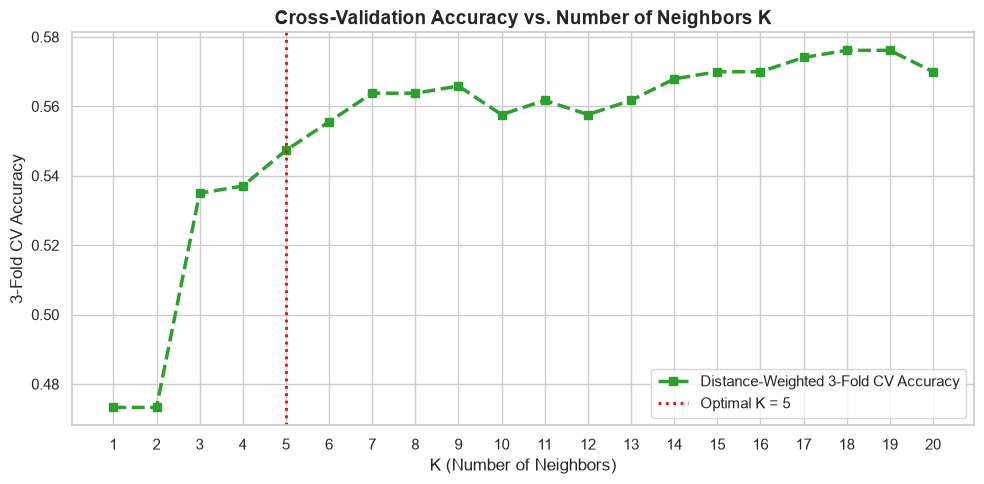

In [7]:
k_range = list(range(1, min(21, len(X_train))))
scores  = []
best_k, best_score = 1, 0.0

for k in k_range:
    knn_cv = KNeighborsClassifier(n_neighbors=k, weights='distance')
    sc = cross_val_score(knn_cv, X_train_s, y_base_train, cv=3).mean()
    scores.append(sc)
    if sc > best_score:
        best_score, best_k = sc, k

optimal_k = max(1, min(best_k, 5))  # cap at 5 to avoid over-smoothing
print(f"CV-best K : {best_k}  (CV accuracy: {best_score:.3f})")
print(f"Optimal K : {optimal_k}  (capped at 5)")

plt.figure(figsize=(10, 5))
plt.plot(k_range, scores, marker='s', linestyle='--', linewidth=2.5,
         color='#2ca02c', label='Distance-Weighted 3-Fold CV Accuracy')
plt.axvline(optimal_k, color='red', linestyle=':', linewidth=2,
            label=f'Optimal K = {optimal_k}')
plt.title('Cross-Validation Accuracy vs. Number of Neighbors K', fontsize=14, fontweight='bold')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('3-Fold CV Accuracy')
plt.xticks(k_range)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Step 6: Model Training & Multi-Tier Accuracy Evaluation

Two KNN models are trained with the same optimal K:

| Model | Label | Role |
|---|---|---|
| knn_base_model | Base_English (33 families) | Stage 1 -- coarse classification |
| knn_fine_model | EnglishName (313 shades) | Single-stage strict-match baseline |

**Metrics are reported separately for three systems:**

1. **Single-stage fine KNN baseline** (313 shade classes)
   - Strict exact match
   - Human-vision Top-1
   - Human-vision Top-3

2. **Stage 1 base KNN** (33 color families)
   - Base-family accuracy

3. **End-to-end two-stage pipeline** (Stage 1 KNN + CIE Lab retrieval)
   - Strict exact match
   - Human-vision Top-1
   - Human-vision Top-3

> Important: the two-stage pipeline is evaluated separately. Its metrics are not
> the same as the fine-KNN baseline, and both are reported below to avoid mixing
> baseline results with end-to-end results.

In [8]:
knn_base_model = KNeighborsClassifier(n_neighbors=optimal_k, weights='distance')
knn_base_model.fit(X_train_s, y_base_train)

knn_fine_model = KNeighborsClassifier(n_neighbors=optimal_k, weights='distance')
knn_fine_model.fit(X_train_s, y_fine_train)

pred_base = knn_base_model.predict(X_test_s)
pred_fine = knn_fine_model.predict(X_test_s)

# ---------------------------------------------------------------------------
# Single-stage fine KNN baseline (313 shade classes)
# ---------------------------------------------------------------------------
strict_acc = accuracy_score(y_fine_test, pred_fine)
base_acc   = accuracy_score(y_base_test, pred_base)

human_matches = sum(
    to_core_family(y_fine_test[i]) == to_core_family(pred_fine[i])
    for i in range(len(y_fine_test))
)
human_acc = human_matches / len(y_fine_test)

_, neighbor_idx = knn_fine_model.kneighbors(X_test_s)
top3 = sum(
    any(to_core_family(y_fine_test[i]) == to_core_family(y_fine_train[neighbor_idx[i][j]])
        for j in range(3))
    for i in range(len(y_fine_test))
)
top3_acc = top3 / len(y_fine_test)

# ---------------------------------------------------------------------------
# End-to-end two-stage pipeline (the same logic used by predict.py)
# Stage 1: KNN -> base family
# Stage 2: CIE Lab Delta-E nearest-neighbor inside that family
# ---------------------------------------------------------------------------
labs_test = labs_all[test_idx]


def two_stage_top3_names(features_scaled, query_lab):
    """Return the top-3 shade names retrieved by the two-stage pipeline."""
    pred_base_en = knn_base_model.predict(features_scaled)[0]
    base_mask = (df_train['Base_English'] == pred_base_en)

    if not np.any(base_mask):
        candidate_sub = df_train
        candidate_labs = labs_train
    else:
        candidate_sub = df_train[base_mask].reset_index(drop=True)
        candidate_labs = labs_train[base_mask.values]

    distances = np.linalg.norm(candidate_labs - query_lab, axis=1)
    order = np.argsort(distances)[:3]
    return candidate_sub.iloc[order]['EnglishName'].tolist()


two_stage_top3 = [
    two_stage_top3_names(X_test_s[i:i + 1], labs_test[i])
    for i in range(len(X_test_s))
]
two_stage_pred = [names[0] for names in two_stage_top3]

two_stage_strict = accuracy_score(y_fine_test, two_stage_pred)
two_stage_human = sum(
    to_core_family(y_fine_test[i]) == to_core_family(two_stage_pred[i])
    for i in range(len(y_fine_test))
) / len(y_fine_test)
two_stage_top3_human = sum(
    any(to_core_family(y_fine_test[i]) == to_core_family(name) for name in names)
    for i, names in enumerate(two_stage_top3)
) / len(y_fine_test)

print("Single-stage fine KNN baseline (313 shade classes)")
print(f"  Strict exact-match accuracy      : {strict_acc * 100:.1f}%")
print(f"  Human-vision accuracy            : {human_acc * 100:.1f}%")
print(f"  Top-3 human-vision accuracy      : {top3_acc * 100:.1f}%")
print()
print("Stage 1 base KNN (33 color families)")
print(f"  Base-family accuracy             : {base_acc * 100:.1f}%")
print()
print("End-to-end two-stage pipeline (Stage 1 + CIE Lab retrieval)")
print(f"  Strict exact-match accuracy      : {two_stage_strict * 100:.1f}%")
print(f"  Human-vision accuracy            : {two_stage_human * 100:.1f}%")
print(f"  Top-3 human-vision accuracy      : {two_stage_top3_human * 100:.1f}%")

Single-stage fine KNN baseline (313 shade classes)
  Strict exact-match accuracy      : 17.2%
  Human-vision accuracy            : 75.4%
  Top-3 human-vision accuracy      : 89.3%

Stage 1 base KNN (33 color families)
  Base-family accuracy             : 59.8%

End-to-end two-stage pipeline (Stage 1 + CIE Lab retrieval)
  Strict exact-match accuracy      : 12.3%
  Human-vision accuracy            : 79.5%
  Top-3 human-vision accuracy      : 80.3%


## Step 7: Confusion Matrix & Error Analysis

The confusion matrix is computed across 14 **core** color families. Both true labels
and predictions are mapped through `to_core_family()`, which collapses compound names
like "Navy Blue" -> "Blue". This reveals genuine cross-family errors.

Notable boundary zones:
- **Teal** straddles Blue and Green
- **Cream / Beige** overlap with White
- **Salmon / Coral** overlap at the Red/Orange/Pink boundary

Two views are shown:
1. **Absolute counts** -- raw sample numbers per cell
2. **Normalized recall** -- fraction of each true class predicted correctly (rows sum to 1)

=== Confusion Matrix (absolute counts) ===


,Blue,Green,Orange,Peach,Yellow,Red,Pink,Purple,Brown,Gray,Black,White,Beige & Cream,Teal
Blue,21,0,0,0,0,0,0,0,0,1,0,0,0,1
Green,0,9,0,0,0,0,0,0,0,1,0,0,0,3
Orange,0,0,12,0,1,1,0,0,1,0,0,0,1,0
Peach,0,0,0,2,0,1,0,0,0,0,0,0,2,0
Yellow,0,0,0,0,10,0,0,0,0,0,0,1,1,0
Red,0,0,0,0,0,7,0,0,0,0,0,0,0,0
Pink,0,0,0,0,0,0,3,0,0,0,0,1,1,0
Purple,0,0,0,0,0,0,0,3,0,0,0,0,0,0
Brown,0,0,0,0,0,1,0,0,3,0,0,0,0,0
Gray,0,0,0,0,0,0,0,0,0,6,1,1,0,0



=== Classification Report ===
               precision    recall  f1-score   support

         Blue       0.95      0.91      0.93        23
        Green       0.90      0.69      0.78        13
       Orange       1.00      0.75      0.86        16
        Peach       1.00      0.40      0.57         5
       Yellow       0.91      0.83      0.87        12
          Red       0.70      1.00      0.82         7
         Pink       1.00      0.60      0.75         5
       Purple       1.00      1.00      1.00         3
        Brown       0.60      0.75      0.67         4
         Gray       0.75      0.75      0.75         8
        Black       0.50      0.50      0.50         2
        White       0.73      0.92      0.81        12
Beige & Cream       0.57      0.89      0.70         9
         Teal       0.20      0.33      0.25         3

     accuracy                           0.80       122
    macro avg       0.77      0.74      0.73       122
 weighted avg       0.84      0.

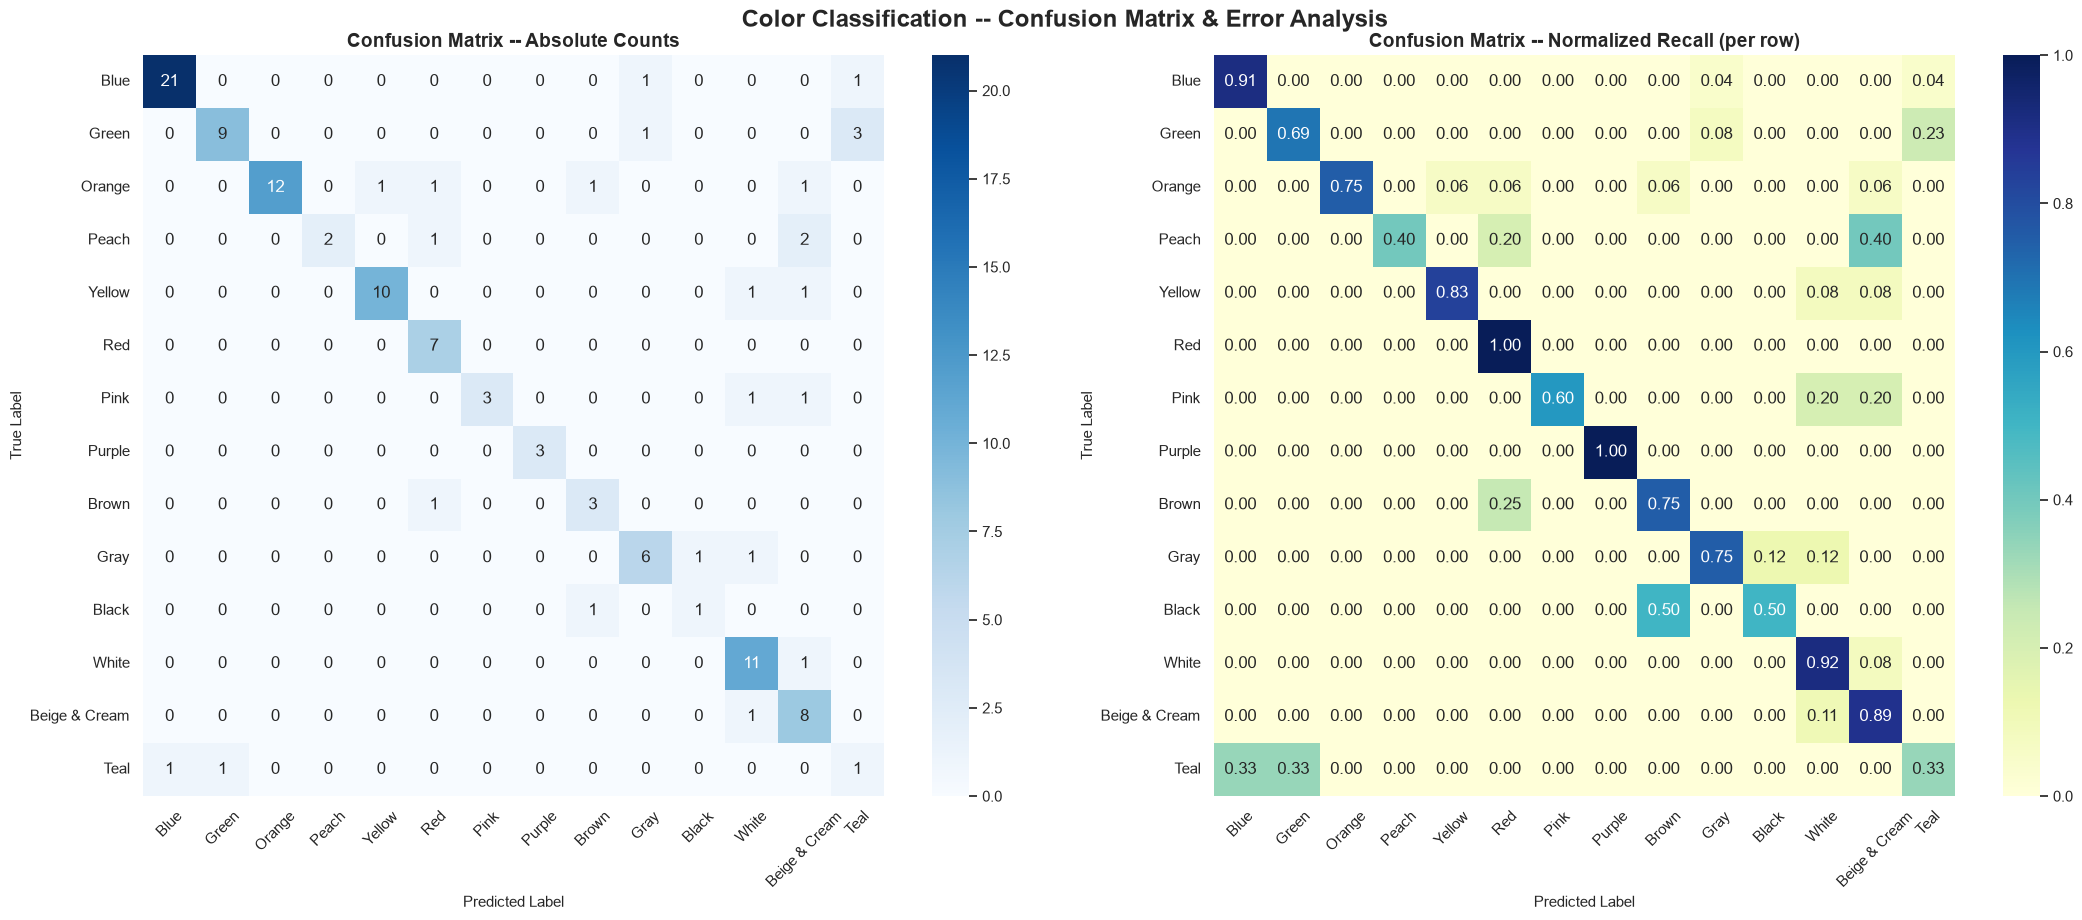

In [9]:
y_core_true = [to_core_family(n) for n in y_fine_test]
y_core_pred = [to_core_family(n) for n in pred_base]

core_labels = ['Blue', 'Green', 'Orange', 'Peach', 'Yellow', 'Red', 'Pink',
               'Purple', 'Brown', 'Gray', 'Black', 'White', 'Beige & Cream', 'Teal']
core_labels = [c for c in core_labels if c in set(y_core_true) or c in set(y_core_pred)]

cm    = confusion_matrix(y_core_true, y_core_pred, labels=core_labels)
df_cm = pd.DataFrame(cm, index=core_labels, columns=core_labels)

print("=== Confusion Matrix (absolute counts) ===")
display(df_cm)
print("\n=== Classification Report ===")
print(classification_report(y_core_true, y_core_pred,
                            labels=core_labels, target_names=core_labels, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, ax=axes[0])
axes[0].set_title('Confusion Matrix -- Absolute Counts', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_norm = np.nan_to_num(cm.astype('float') / cm.sum(axis=1)[:, np.newaxis])
df_cm_n = pd.DataFrame(cm_norm, index=core_labels, columns=core_labels)

sns.heatmap(df_cm_n, annot=True, fmt='.2f', cmap='YlGnBu', cbar=True, square=True, ax=axes[1])
axes[1].set_title('Confusion Matrix -- Normalized Recall (per row)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Color Classification -- Confusion Matrix & Error Analysis',
             fontsize=17, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 8: Visual Test Swatches -- Actual vs. Predicted

A random sample of 16 test colors is displayed. Each swatch shows:
- **True label** (actual color name)
- **Predicted label** (model's prediction)
- **Match type:** EXACT MATCH (green badge), VISUAL MATCH (blue badge), or MISMATCH (red badge)

A "VISUAL MATCH" means the prediction is a different shade name but the same core color family --
which is acceptable from a human-perception standpoint.

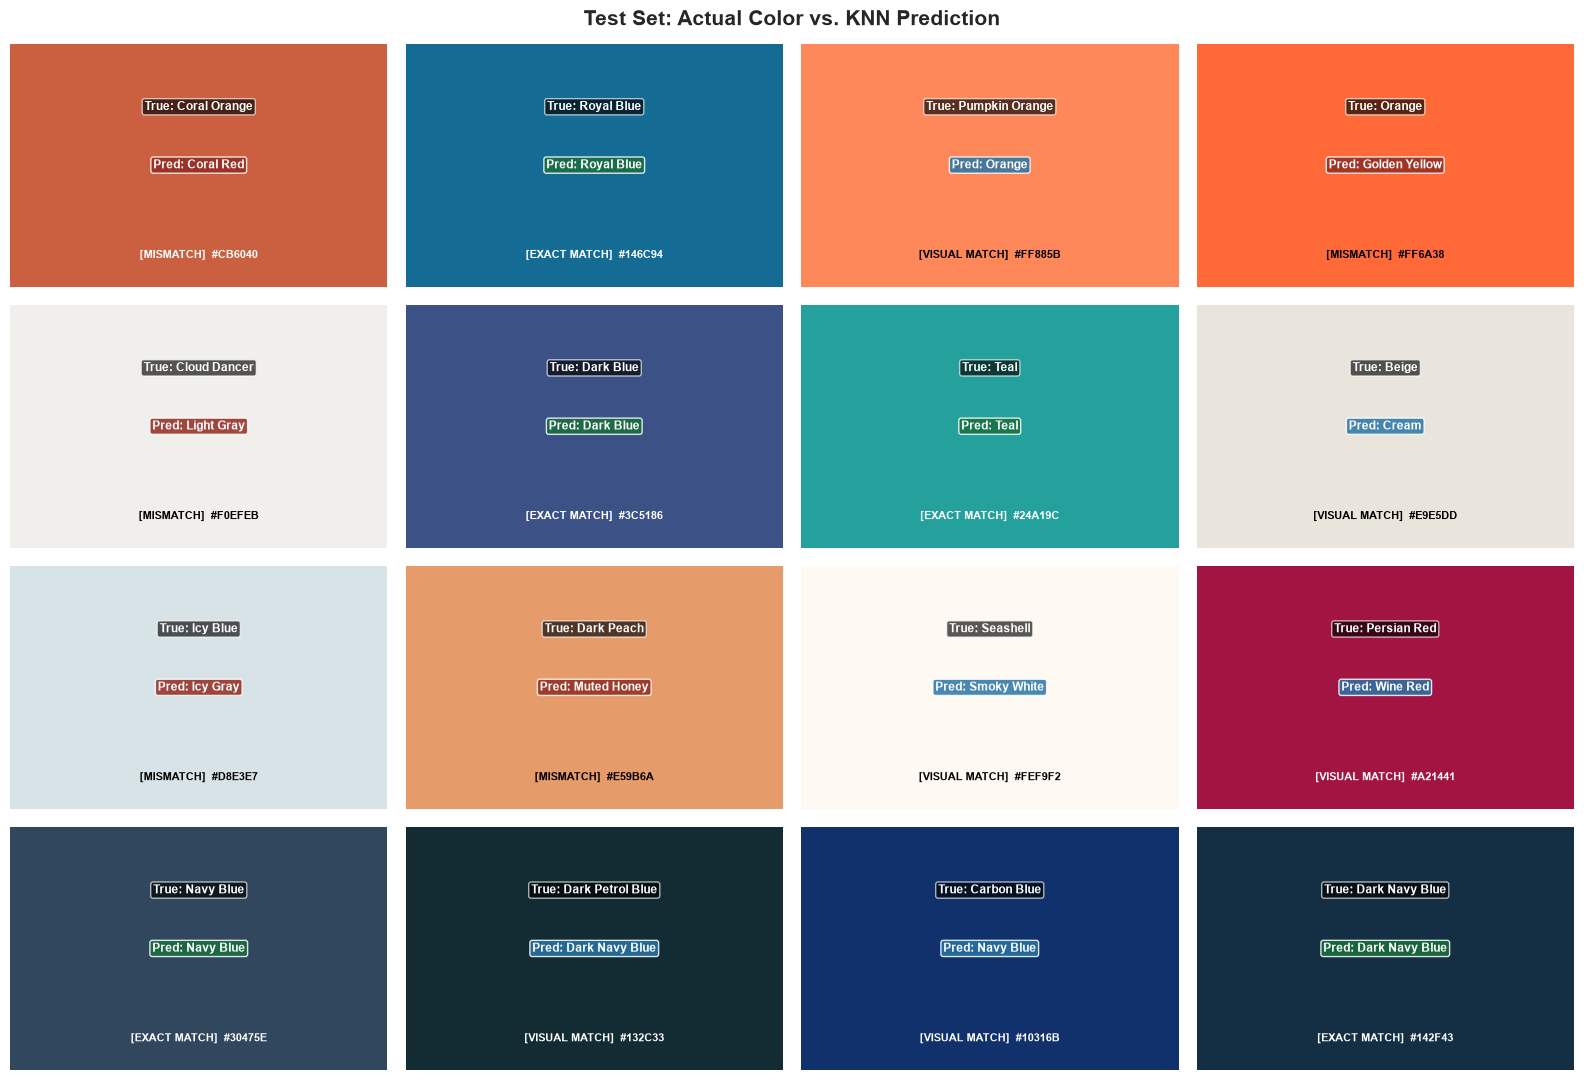

In [10]:
sample_idxs = np.random.RandomState(42).choice(len(y_fine_test), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for ax_idx, s_idx in enumerate(sample_idxs):
    r_idx, c_idx = divmod(ax_idx, 4)
    ax = axes[r_idx, c_idx]

    true_label = y_fine_test[s_idx]
    pred_label = pred_fine[s_idx]

    is_exact = (true_label == pred_label)
    is_human = (to_core_family(true_label) == to_core_family(pred_label))

    match_row = df_colors[df_colors['name'] == true_label]
    hex_code  = match_row['hex'].iloc[0] if len(match_row) > 0 else '#888888'
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=hex_code))

    # Use perceptual luminance for text contrast (not string comparison)
    rv, gv, bv = hex_to_rgb(hex_code)
    lum = (0.299 * rv + 0.587 * gv + 0.114 * bv) / 255.0
    tc = 'black' if lum > 0.5 else 'white'

    if is_exact:
        badge = '#196F3D'; status = "EXACT MATCH"
    elif is_human:
        badge = '#2874A6'; status = "VISUAL MATCH"
    else:
        badge = '#922B21'; status = "MISMATCH"

    ax.text(0.5, 0.74, f"True: {true_label}",
            ha='center', va='center', color='white', fontsize=8.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.65))
    ax.text(0.5, 0.50, f"Pred: {pred_label}",
            ha='center', va='center', color='white', fontsize=8.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor=badge, alpha=0.85))
    ax.text(0.5, 0.13, f"[{status}]  {hex_code}",
            ha='center', va='center', color=tc, fontsize=8, fontweight='bold')

    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

plt.suptitle('Test Set: Actual Color vs. KNN Prediction', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 9: Pipeline Serialization

The full pipeline is saved to `model.pkl` via joblib. Contents:

| Key | Description |
|---|---|
| knn_base_model | Stage 1 KNN (predicts base color family) |
| model | Stage 2 KNN (predicts exact shade name) |
| scaler | Fitted StandardScaler |
| train_df | Training split of the dataset (used for Stage 2 retrieval) |
| labs_train | CIE Lab coordinates of all training samples |
| base_en_to_fa | English to Persian mapping for base families |
| en_to_fa | English to Persian mapping for all 313 shade names |

> model.pkl is excluded from the git repository. Run `train.py` to regenerate it locally.

In [11]:
base_en_to_fa = dict(zip(df_colors['Base_English'], df_colors['Base_Persian']))

pipeline_data = {
    "model":                   knn_fine_model,
    "knn_base_model":          knn_base_model,
    "scaler":                  scaler,
    "train_df":                df_train,
    "labs_train":              labs_train,
    "base_en_to_fa":           base_en_to_fa,
    "en_to_fa":                en_to_fa,
    "confusion_matrix":        cm,
    "confusion_matrix_labels": core_labels,
    "confusion_matrix_df":     df_cm,
}
joblib.dump(pipeline_data, "model.pkl")
print("Saved: model.pkl")

Saved: model.pkl


## Step 10: Two-Stage Live Inference Demo

For each test hex code:
1. **Stage 1** -- KNN classifies it into a base color family using the 6-dim feature vector.
2. **Stage 2** -- CIE Lab Delta-E search finds the perceptually closest shade within that family.

Each swatch shows the hex code, Stage 1 result, Stage 2 result (with Persian name), and Delta-E.
Smaller Delta-E means the match is perceptually closer.

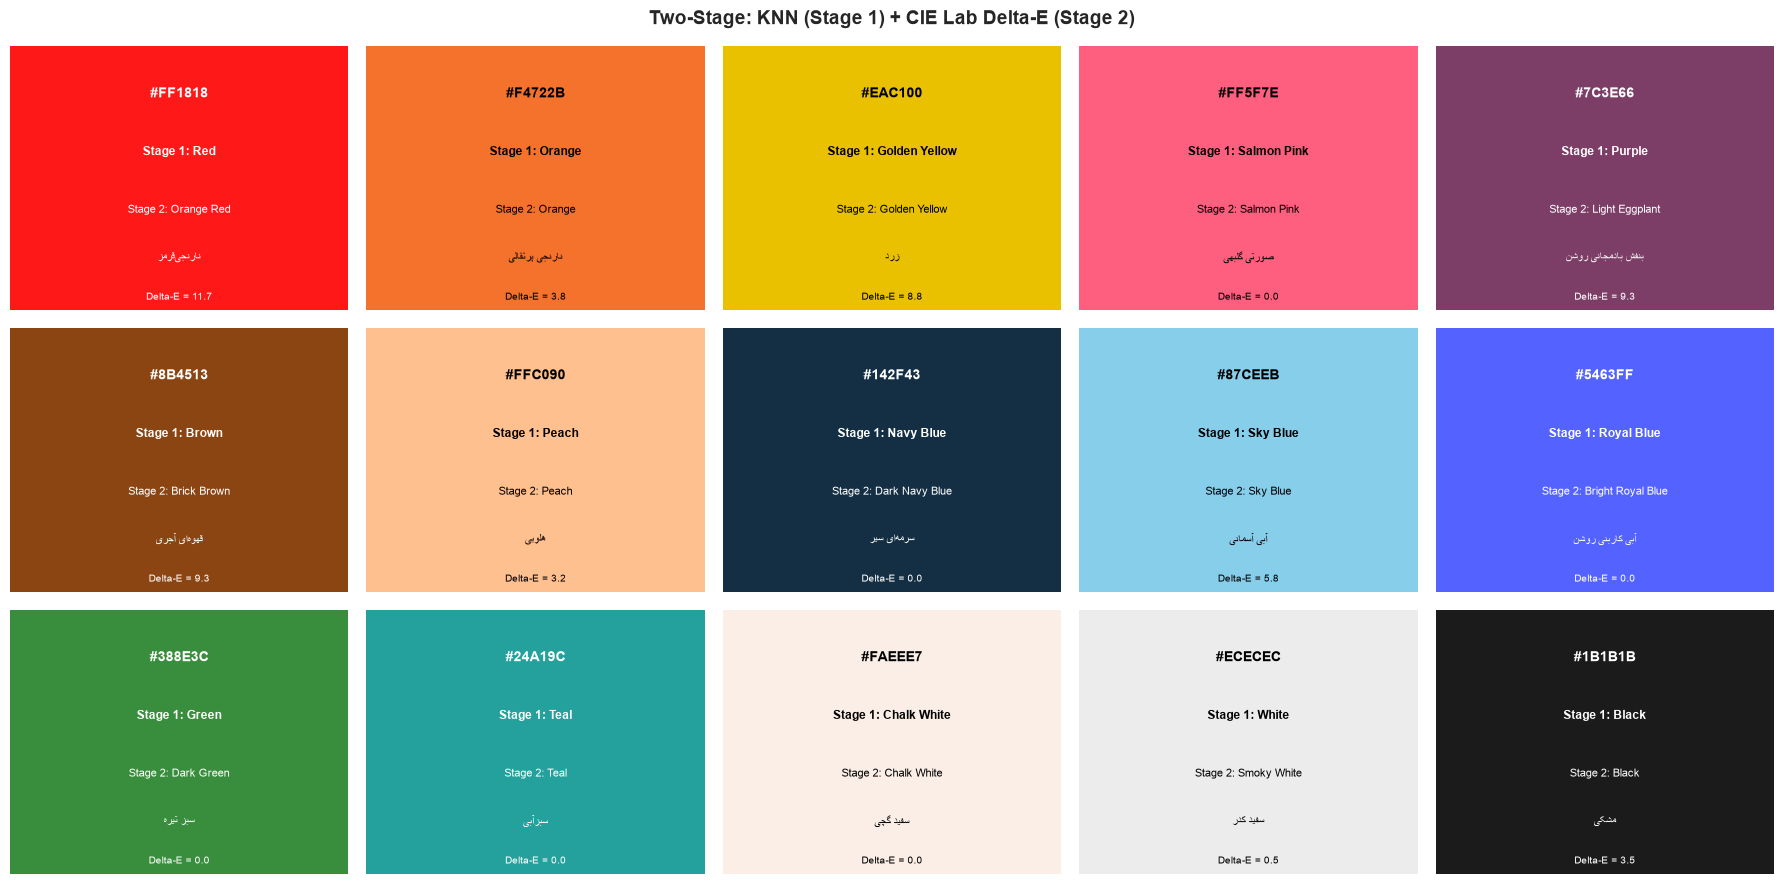

,Hex,Base (EN),Base (FA),Shade (EN),Shade (FA),Delta-E
0,#FF1818,Red,قرمز,Orange Red,نارنجی‌قرمز,11.66
1,#F4722B,Orange,نارنجی,Orange,نارنجی پرتقالی,3.79
2,#EAC100,Golden Yellow,زرد طلایی,Golden Yellow,زرد,8.85
3,#FF5F7E,Salmon Pink,صورتی گلبهی,Salmon Pink,صورتی گلبهی,0.00
4,#7C3E66,Purple,بنفش,Light Eggplant,بنفش بادمجانی روشن,9.29
5,#8B4513,Brown,قهوه‌ای,Brick Brown,قهوه‌ای آجری,9.30
6,#FFC090,Peach,هلویی,Peach,هلویی,3.21
7,#142F43,Navy Blue,سرمه‌ای,Dark Navy Blue,سرمه‌ای سیر,0.00
8,#87CEEB,Sky Blue,آبی آسمانی,Sky Blue,آبی آسمانی,5.76
9,#5463FF,Royal Blue,آبی کاربنی,Bright Royal Blue,آبی کاربنی روشن,0.00


In [12]:
test_colors = [
    "#FF1818",  # Bright Red          (warm)
    "#F4722B",  # Dark Orange          (warm)
    "#EAC100",  # Amber Yellow         (warm)
    "#FF5F7E",  # Salmon Pink          (warm)
    "#7C3E66",  # Plum Purple          (warm)
    "#8B4513",  # Chocolate Brown      (warm)
    "#FFC090",  # Peach                (warm)
    "#142F43",  # Dark Navy Blue       (cool)
    "#87CEEB",  # Sky Blue             (cool)
    "#5463FF",  # Bright Royal Blue    (cool)
    "#388E3C",  # Dark Green           (cool)
    "#24A19C",  # Teal                 (cool)
    "#FAEEE7",  # Chalk White          (neutral)
    "#ECECEC",  # Light Gray           (neutral)
    "#1B1B1B",  # Charcoal Black       (neutral)
]

results = []
fig, axes = plt.subplots(3, 5, figsize=(18, 9))

for i, hex_code in enumerate(test_colors):
    r, g, b = hex_to_rgb(hex_code)
    feat_scaled = scaler.transform([hex_to_features(hex_code)])
    query_lab   = np.array(rgb_to_lab(r, g, b))

    # Stage 1: KNN -> base family
    pred_base_en = knn_base_model.predict(feat_scaled)[0]
    pred_base_fa = base_en_to_fa.get(pred_base_en, pred_base_en)

    # Stage 2: CIE Lab Delta-E nearest-neighbor within the predicted family
    mask      = (df_train['Base_English'] == pred_base_en)
    cand_sub  = df_train[mask]  if mask.any() else df_train
    cand_labs = labs_train[mask.values] if mask.any() else labs_train
    dists     = np.linalg.norm(cand_labs - query_lab, axis=1)
    best      = cand_sub.iloc[np.argmin(dists)]
    delta_e   = dists.min()

    results.append((hex_code, pred_base_en, pred_base_fa,
                    best['EnglishName'], best['Persian Name'], round(delta_e, 2)))

    r_idx, c_idx = divmod(i, 5)
    ax = axes[r_idx, c_idx]
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=hex_code))
    lum = (0.299 * r + 0.587 * g + 0.114 * b) / 255.0
    tc  = 'black' if lum > 0.5 else 'white'
    ax.text(0.5, 0.82, hex_code,                           ha='center', va='center', color=tc, fontsize=10, fontweight='bold')
    ax.text(0.5, 0.60, f"Stage 1: {pred_base_en}",         ha='center', va='center', color=tc, fontsize=8.5, fontweight='bold')
    ax.text(0.5, 0.38, f"Stage 2: {best['EnglishName']}",  ha='center', va='center', color=tc, fontsize=8)
    ax.text(0.5, 0.20, f"{best['Persian Name']}",          ha='center', va='center', color=tc, fontsize=8)
    ax.text(0.5, 0.05, f"Delta-E = {delta_e:.1f}",         ha='center', va='center', color=tc, fontsize=7.5)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

plt.suptitle('Two-Stage: KNN (Stage 1) + CIE Lab Delta-E (Stage 2)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

pd.DataFrame(results, columns=['Hex', 'Base (EN)', 'Base (FA)', 'Shade (EN)', 'Shade (FA)', 'Delta-E'])

## Step 11: Conclusions

### Confusion Matrix Key Findings (14 core families)
- **Purple (F1 = 1.00), Blue (0.93), Yellow (0.87), Orange (0.86), Red (0.82),
  and White (0.81)** are the strongest families.
- **Teal (F1 = 0.25)** shows natural overlap with both Blue and Green -- a genuine
  perceptual boundary.
- **Peach (recall = 0.40)** is confused with Beige & Cream and Red; its precision
  remains 1.00 because it is never predicted for other families.
- **Beige & Cream ↔ White** and **Pink ↔ White/Beige** share soft boundaries.
- **Black** has only 2 test samples, so its score is high-variance.

### Baseline vs End-to-End Two-Stage Performance

| System | Target | Strict Exact | Human-Vision Top-1 | Human-Vision Top-3 |
|---|---:|---:|---:|---:|
| Single-stage fine KNN | 313 shade names | 17.2% | 75.4% | 89.3% |
| Single-stage 1-NN in CIE Lab (controlled ablation) | 313 shade names, no family filter | 12.3% | 81.1% | 92.6% |
| Stage 1 base KNN | 33 color families | -- | -- | -- *(base accuracy: 59.8%)* |
| **End-to-end two-stage pipeline** | **33 families + exact shade** | **12.3%** | **79.5%** | **80.3%** |

The two-stage pipeline improves human-vision Top-1 accuracy by **+4.1 points**
over the fine-KNN baseline (75.4% → 79.5%). It does **not** improve strict exact
match or Top-3. The controlled ablation uses the same CIE Lab retrieval space as
Stage 2 but searches the whole training set without the family filter; it reaches
**81.1% / 92.6%**. The family restriction therefore does not by itself improve
retrieval accuracy on this split. Its value is an interpretable, family-consistent
decision path with an explicit failure mode, not a higher retrieval score.

### Why Two Stages Help
Resolving the broad color family first (Stage 1) reduces the 313-way problem to a
33-way problem and prevents cross-family retrieval. The CIE Lab Delta-E metric then
selects the perceptually closest available shade inside the predicted family. The
design's value is interpretability and a family-consistent candidate set; the
ablation above shows that raw retrieval accuracy is not improved by the restriction
on this split.

### Dataset
This notebook uses the **KopolArt Color Collection** (<https://kopolart.ir/colors>),
curated by **Ali Yousefi (KopolArt)** and licensed under **CC BY 4.0**. If you reuse
the dataset, credit **کپل‌آرت – Ali Yousefi** and link to the source.